In [1]:
import numpy as np
import torch
import math
from torch import nn
import torch.nn.functional as F
from torch import distributions as pyd

from utils import util
import pandas as pd
import matplotlib as mpl
from matplotlib import pyplot as plt
from sklearn.decomposition import NMF
from maze.MM_Maze_Utils import *
from maze.MM_Plot_Utils import *
from maze.MM_Traj_Utils import *
from sklearn.decomposition import PCA

In [2]:
origin_phi = np.load('./labyrinth/phi_matrix.npy')
print(origin_phi.shape)

(127, 4, 127)


In [3]:
def draw_phi_with_arrow(maze, origin_phi, real_P, dim, n_sa):
    real_P = np.load('./trans_probs(1).npy')
    n_state, n_action = real_P.shape[0], real_P.shape[1]
    feature_dim = 127
    real_P_reshape = real_P.reshape(n_state, n_action, n_state, 1)
    phi_mat = origin_phi.reshape(n_state, n_action, 1, feature_dim)
    aggregate_phi_origin = (real_P_reshape*phi_mat).sum(0).sum(0)

    f = aggregate_phi_origin[:,dim]
    def normalize_sprime(x):
        return (x - np.min(aggregate_phi_origin)) / (np.max(aggregate_phi_origin) - np.min(aggregate_phi_origin))
    f = normalize_sprime(f)
    sprime_cmap = mpl.cm.get_cmap('Purples')
    v_color = sprime_cmap(np.arange(256))
    v_and_color = np.zeros((v_color.shape[0], 4))
    v_and_color[:, 0] = np.linspace(0, 1, 256)
    v_and_color[:, 1:] = v_color[: , :3]
    fig, ax = plt.subplots(1, 1, figsize=(6, 6))
    PlotMazeFunction(f, maze, mode='nodes', numcol=None, figsize=4, axes=ax, col=v_and_color)
    
    phi_sa = origin_phi.reshape(n_state * n_action, feature_dim)
    phi_sa_idx = np.argsort(phi_sa, axis=0)[-n_sa:, dim]
    s_idx = phi_sa_idx // n_action
    a_idx = phi_sa_idx % n_action
    s_prime_idx = real_P[s_idx, a_idx, :].argmax(-1)
    assert s_idx.shape == a_idx.shape == s_prime_idx.shape
    r = 0.3
    for i in range(len(s_idx)):
        r_s = maze.ru[s_idx[i]]
        x_s = maze.xc[r_s[-1]]
        y_s = maze.yc[r_s[-1]]
        r_sprime = maze.ru[s_prime_idx[i]]
        x_sprime = maze.xc[r_sprime[-1]]
        y_sprime = maze.yc[r_sprime[-1]]
        delta_x = np.clip(x_sprime - x_s, -0.35, 0.35)
        delta_y = np.clip(y_sprime - y_s, -0.35, 0.35)
        if delta_x == 0 and delta_y == 0:
            ax.annotate(
                '',                     # 不画文本
                xy=(x_sprime-0.2, y_sprime-r),          # 箭头指向（终点）
                xytext=(x_sprime-0.2, y_sprime+r),      # 箭头起点
                arrowprops=dict(
                    arrowstyle='-|>,head_length=0.3,head_width=0.3',   # 箭头样式
                    connectionstyle='arc3,rad=1.5',                # 半圆：rad≈1
                    color='red',
                    lw=1.8
                )
            )   
        else:
            ax.arrow(x_sprime-delta_x*3, y_sprime-delta_y*3, delta_x, delta_y,
                head_width=0.3, head_length=0.2, fc='red', ec='red',
                width=0.1)
    save_path = f'./labyrinth/appendix/origin_phi_{dim}_{n_sa}.pdf'
    plt.savefig(save_path, dpi=400)

/tmp/ipykernel_176972/2112402115.py:13: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  sprime_cmap = mpl.cm.get_cmap('Purples')


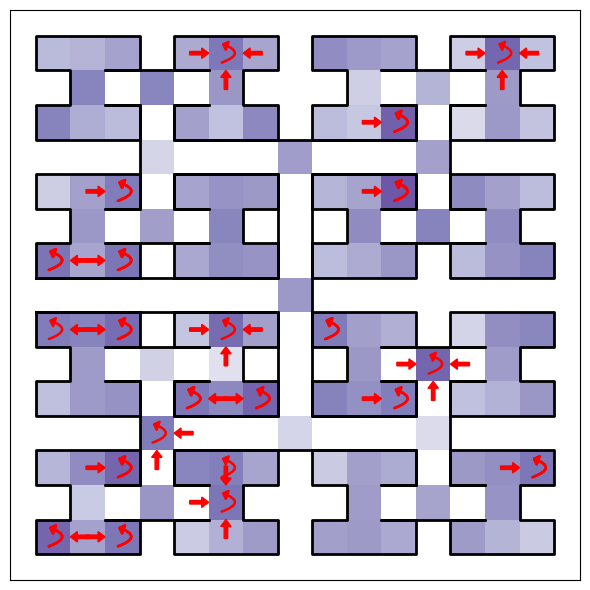

In [4]:
real_P = np.load('./trans_probs(1).npy')
n_state, n_action = real_P.shape[0], real_P.shape[1]
feature_dim = 127
real_P = real_P.reshape(n_state, n_action, n_state, 1)
phi_mat = origin_phi.reshape(n_state, n_action, 1, feature_dim)
aggregate_phi_origin = (real_P*phi_mat).sum(0).sum(0)
maze = NewMaze(6)

draw_phi_with_arrow(maze, origin_phi, real_P, dim=0, n_sa=80)

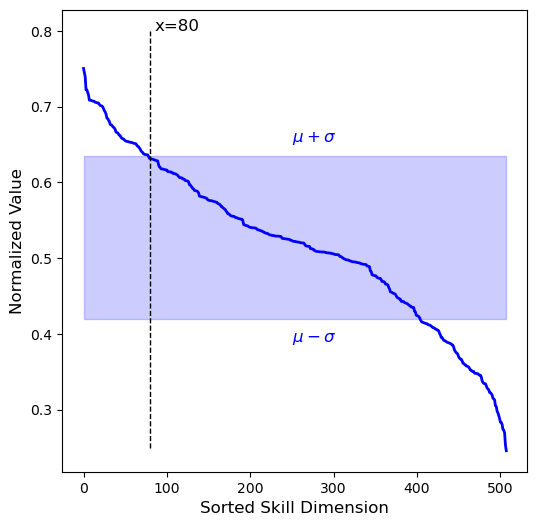

In [5]:
normalized_origin_phi = (origin_phi - np.min(origin_phi))/(np.max(origin_phi) - np.min(origin_phi))
phi_dim = normalized_origin_phi.reshape(n_state * n_action, feature_dim)[:,0]
# normalize_phi_dim = (phi_dim - np.min(origin_phi))/(np.max(origin_phi) - np.min(origin_phi))
sort_phi_dim = np.sort(phi_dim)[::-1]
fig, ax = plt.subplots(1, 1, figsize=(6, 6))
ax.plot(np.arange(len(sort_phi_dim)), sort_phi_dim, color='blue', linewidth=2)
mu = np.mean(normalized_origin_phi)
ax.vlines(x=80, ymin=0.25, ymax=0.8, color='k', linestyle='--', linewidth=1)
sigma = np.std(normalized_origin_phi)
ax.fill_between(np.arange(len(sort_phi_dim)), mu-sigma, mu+sigma, color='blue', alpha=0.2)
ax.annotate('$\mu+\sigma$', xy=(0, mu+sigma), xytext=(250, mu+sigma+0.02),
            fontsize=12, color='blue')
ax.annotate('$\mu-\sigma$', xy=(0, mu-sigma), xytext=(250, mu-sigma-0.03),
            fontsize=12, color='blue')
ax.annotate('x=80', xy=(80, 0.8), xytext=(85, 0.8),
            fontsize=12, color='k')
ax.set_xlabel('Sorted Skill Dimension', fontsize=12)
ax.set_ylabel('Normalized Value', fontsize=12)
plt.savefig('./labyrinth/appendix/origin_phi_curve_0.pdf', dpi=400)

In [6]:
sorted_normalized_origin_phi = np.sort(normalized_origin_phi.reshape(-1, feature_dim), axis=0)[::-1]
effective_dim_origin = np.where(sorted_normalized_origin_phi>mu+sigma, 1, 0).sum(0)
print(effective_dim_origin)

[ 79  77  61  74  55  82  51  94  78  72  57  96  78  72  72  72  74  86
  70  63  55  84  92  61  68  97  78  98  62  79  70  89  88  78  80  78
  88  54  92  85  70  80  78  82 104  62  60  90  84  74  90  87 101  83
  92  69  89  99  81  75  58  89  59 114  78  88  53  80  98  90  67  83
 108  89  96 101  65  67  75  61 106  78  78 110  96  78  45  86  78  69
  65  90  97  83 101  60  96  86  70 108  90  86  55  67  92  65  96  76
  80  50  63  93  61 106  85  65  87  91  58  92  87  82  71  76  84  75
  92]


After PCA

In [7]:
pca = PCA(n_components=127)
flatten_phi = origin_phi.reshape(-1, 127)
# agg_phi_transpose = agg_phi.T # [n_samples, n_features]
flatten_phi_transformed = pca.fit_transform(flatten_phi)
phi_transformed = flatten_phi_transformed.reshape(127,4,127)

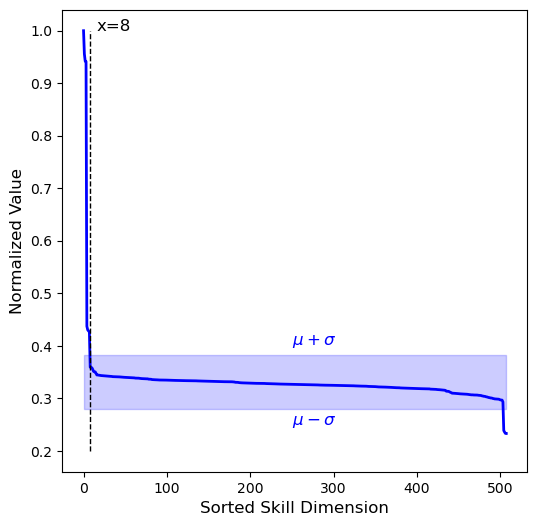

In [8]:
normalized_flatten_phi_transformed = (flatten_phi_transformed - np.min(flatten_phi_transformed))/(np.max(flatten_phi_transformed) - np.min(flatten_phi_transformed))
phi_dim = normalized_flatten_phi_transformed[:,0]
# normalized_phi_dim = (phi_dim - flatten_phi_transformed.min())/(flatten_phi_transformed.max() - flatten_phi_transformed.min())
sort_phi_dim = np.sort(phi_dim)[::-1]
fig, ax = plt.subplots(1, 1, figsize=(6, 6))
ax.plot(np.arange(len(sort_phi_dim)), sort_phi_dim, color='blue', linewidth=2)
ax.vlines(x=8, ymin=0.2, ymax=1, color='k', linestyle='--', linewidth=1)
ax.annotate('x=8', xy=(8, 1), xytext=(15, 1),
            fontsize=12, color='k')
mu = np.mean(normalized_flatten_phi_transformed)
sigma = np.std(normalized_flatten_phi_transformed)
ax.fill_between(np.arange(len(sort_phi_dim)), mu-sigma, mu+sigma, color='blue', alpha=0.2)
ax.annotate('$\mu+\sigma$', xy=(0, mu+sigma), xytext=(250, mu+sigma+0.02),
            fontsize=12, color='blue')
ax.annotate('$\mu-\sigma$', xy=(0, mu-sigma), xytext=(250, mu-sigma-0.03),
            fontsize=12, color='blue')
ax.set_xlabel('Sorted Skill Dimension', fontsize=12)
ax.set_ylabel('Normalized Value', fontsize=12)
plt.savefig('./labyrinth/appendix/pc_skill_curve_0.pdf', dpi=400)

In [9]:
sorted_normalized_phi_transformed = np.sort(normalized_flatten_phi_transformed, axis=0)[::-1]
effective_dim_transformed = np.where(sorted_normalized_phi_transformed>mu+sigma, 1, 0).sum(0)
print(effective_dim_transformed)

[ 8  4 12 12  9 12 20 30 28 36 34 37 37 45 44 44 40 40 46 59 56 46 42 39
 47 43 51 52 57 36 49 48 41 44 33 41 44 47 46 38 44 48 45 28 48 60 55 49
 45 37 52 43 48 47 43 47 40 47 39 46 45 35 42 53 36 54 37 50 33 40 33 61
 40 28 52 43 39 48 41 31 51 38 44 39 21 46 40 51 31 40 36 33 36 48 28 41
 33 40 33 23 35 26 40 25 35 28 33 30 32 24 25 36 23 24 16 17 26 20 18 21
 24 12  8  8  4  4  0]


/tmp/ipykernel_176972/2112402115.py:13: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  sprime_cmap = mpl.cm.get_cmap('Purples')


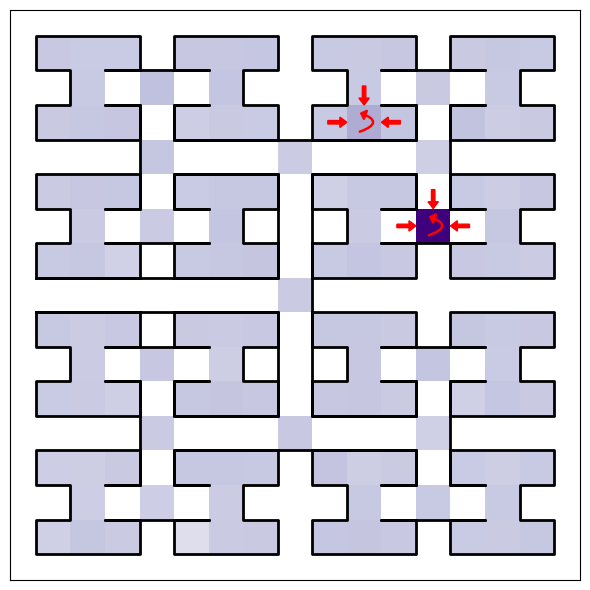

In [10]:
normalized_phi = normalized_flatten_phi_transformed.reshape(127,4,127)
draw_phi_with_arrow(maze, normalized_phi, real_P, dim=0, n_sa=8)